# Boralesgamuwa UWC – EDA and Preprocessing

In [1]:
import os
from math import sqrt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import xgboost
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [2]:
plt.rcParams["figure.figsize"] = (18, 5)
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)

## 1. Load the raw dataset

In [3]:
NAME = "Boralasgamuwa"
DATA_PATH = "boralasgamuwa_uc_2012-2018.csv"
df = pd.read_csv(DATA_PATH)

In [4]:
print(df.shape)

(2988, 4)


In [5]:
df.head(10)

,area,ticket_date,waste_type,net_weight_kg
0,Boralesgamuwa UC,2012-01-01,MSW,17340.0
1,Boralesgamuwa UC,2012-01-02,MSW,25980.0
2,Boralesgamuwa UC,2012-01-03,MSW,29220.0
3,Boralesgamuwa UC,2012-01-04,MSW,7450.0
4,Boralesgamuwa UC,2012-01-05,MSW,10520.0
5,Boralesgamuwa UC,2012-01-06,MSW,29260.0
6,Boralesgamuwa UC,2012-01-07,MSW,11820.0
7,Boralesgamuwa UC,2012-01-08,MSW,20680.0
8,Boralesgamuwa UC,2012-01-09,MSW,23940.0
9,Boralesgamuwa UC,2012-01-10,MSW,23330.0


In [6]:
df.describe()

,net_weight_kg
count,2988.000000
mean,22159.832664
std,12825.464915
min,0.000000
25%,12767.500000
50%,23905.000000
75%,30682.500000
max,215040.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2988 entries, 0 to 2987
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   area           2988 non-null   object 
 1   ticket_date    2988 non-null   object 
 2   waste_type     2988 non-null   object 
 3   net_weight_kg  2988 non-null   float64
dtypes: float64(1), object(3)
memory usage: 93.5+ KB


In [8]:
print("Missing values per column:\n", df.isna().sum())

Missing values per column:
 area             0
ticket_date      0
waste_type       0
net_weight_kg    0
dtype: int64


In [9]:
print("\nExact duplicate rows:", df.duplicated().sum())


Exact duplicate rows: 0


In [10]:
print("Duplicate (date, waste_type) rows:", df.duplicated(["ticket_date", "waste_type"]).sum())

Duplicate (date, waste_type) rows: 0


In [11]:
print("Zero-weight rows:", (df["net_weight_kg"] == 0).sum(), "| negative:", (df["net_weight_kg"] < 0).sum())

Zero-weight rows: 5 | negative: 0


In [12]:
wt = df.groupby("waste_type")["net_weight_kg"].agg(rows="count", total_kg="sum", mean_kg="mean")

In [13]:
wt["share_%"] = (wt["total_kg"] / wt["total_kg"].sum() * 100).round(2)
wt.sort_values("total_kg", ascending=False)

,rows,total_kg,mean_kg,share_%
waste_type,,,,
MSW,2417,62870940.0,26011.973521,94.95
Sorted Organic Waste,571,3342640.0,5854.010508,5.05


In [14]:
df.pivot_table(index=df["ticket_date"].str[:4], columns="waste_type", values="net_weight_kg",
                aggfunc="sum", fill_value=0).astype(int)

waste_type,MSW,Sorted Organic Waste
ticket_date,,
2012,8981740,0
2013,9246230,0
2014,9730880,0
2015,11240260,0
2016,7045750,392550
2017,9384440,738840
2018,7241640,2211250


All waste types are summed into one daily total, as in the original pipeline.

## 2. Fix the day/month swap (per year)

In [15]:
iso = pd.to_datetime(df["ticket_date"], format="%Y-%m-%d")
ydm = pd.to_datetime(df["ticket_date"], format="%Y-%d-%m", errors="coerce")
ambiguous = (iso.dt.day <= 12) & (iso.dt.day != iso.dt.month)
kg = df["net_weight_kg"]
reference = kg[~ambiguous].groupby(iso[~ambiguous]).sum()

In [16]:
def same_weekday_deviation(dates, mask):
    totals = kg[mask].groupby(dates[mask]).sum()
    devs = []
    for day, value in totals.items():
        neighbours = reference.reindex([day + pd.Timedelta(weeks=k) for k in (-3, -2, -1, 1, 2, 3)]).dropna()
        if len(neighbours) >= 2 and neighbours.median() > 0:
            devs.append(abs(value - neighbours.median()) / neighbours.median())
    return np.median(devs) if devs else np.nan

def weekend_ratio(dates, mask):
    d = kg[mask].groupby(dates[mask]).sum()
    p = d.groupby(d.index.dayofweek).mean()
    return p.reindex([5, 6]).mean() / p.reindex(range(5)).mean()

year_str = df["ticket_date"].str[:4]
rows = []
for y in sorted(year_str.unique()):
    m = (year_str == y) & ambiguous
    dev_iso, dev_ydm = same_weekday_deviation(iso, m), same_weekday_deviation(ydm, m)
    rows.append({"year": y, "ambiguous rows": int(m.sum()),
                 "weekend ratio (day>12)": weekend_ratio(iso, (year_str == y) & ~ambiguous),
                 "weekend ratio as stored": weekend_ratio(iso, m),
                 "weekend ratio swapped": weekend_ratio(ydm, m),
                 "deviation as stored": dev_iso, "deviation swapped": dev_ydm,
                 "swap": bool(dev_ydm < dev_iso)})
swap_test = pd.DataFrame(rows).set_index("year")
swap_test.round(3)

,ambiguous rows,weekend ratio (day>12),weekend ratio as stored,weekend ratio swapped,deviation as stored,deviation swapped,swap
year,,,,,,,
2012,132,0.522,1.042,0.617,0.226,0.118,True
2013,132,0.604,1.035,0.615,0.241,0.133,True
2014,132,0.689,0.984,0.637,0.240,0.154,True
2015,127,0.651,0.982,0.624,0.268,0.188,True
2016,136,0.685,0.981,0.693,0.245,0.113,True
2017,211,0.751,1.007,0.738,0.205,0.164,True
2018,200,0.705,1.045,0.731,0.249,0.164,True


In [17]:
SWAP_YEARS = swap_test.index[swap_test["swap"]].tolist()
print("Years where day <= 12 dates are swapped:", SWAP_YEARS)
print("Years kept as stored:", swap_test.index[~swap_test["swap"]].tolist())

Years where day <= 12 dates are swapped: ['2012', '2013', '2014', '2015', '2016', '2017', '2018']
Years kept as stored: []


In [18]:
df["ticket_date_original"] = df["ticket_date"]
df["date_swapped"] = ambiguous & year_str.isin(SWAP_YEARS)
df["ticket_date"] = iso.where(~df["date_swapped"], ydm)

In [19]:
print("Rows with swapped date:", int(df["date_swapped"].sum()))
print("Duplicate keys after fix:", df.duplicated(["ticket_date", "waste_type"] if "waste_type" in df else ["ticket_date"]).sum())
print("Date range after fix:", df["ticket_date"].min().date(), "to", df["ticket_date"].max().date())

Rows with swapped date: 1070
Duplicate keys after fix: 0
Date range after fix: 2012-01-01 to 2018-12-31


## 3. EDA on the corrected daily series

In [20]:
daily = df.groupby("ticket_date")["net_weight_kg"].sum()       # waste types summed into one daily total
full_range = pd.date_range(daily.index.min(), daily.index.max(), freq="D")
missing_days = full_range.difference(daily.index)

print("Days with data:", len(daily), "| calendar days:", len(full_range), "| missing days:", len(missing_days))
print("Missing days per year:", pd.Series(missing_days.year).value_counts().sort_index().to_dict())
daily.describe()

Days with data: 2417 | calendar days: 2557 | missing days: 140
Missing days per year: {2014: 16, 2015: 8, 2016: 95, 2017: 1, 2018: 20}


,net_weight_kg
count,2417.000000
mean,27394.944146
std,10719.499725
min,0.000000
25%,22060.000000
50%,28210.000000
75%,33100.000000
max,215040.000000


In [21]:
# Days present per year x month
present = pd.Series(daily.index)
present.groupby([present.dt.year, present.dt.month]).size().unstack(fill_value=0)

ticket_date,1,2,3,4,5,6,7,8,9,10,11,12
ticket_date,,,,,,,,,,,,
2012,31,29,31,30,31,30,31,31,30,31,30,31
2013,31,28,31,30,31,30,31,31,30,31,30,31
2014,31,28,31,30,31,30,31,31,30,15,30,31
2015,31,28,29,30,28,30,31,31,30,28,30,31
2016,31,29,31,30,15,0,0,13,30,31,30,31
2017,30,28,31,30,31,30,31,31,30,31,30,31
2018,14,28,30,30,31,30,31,31,30,31,30,29


In [22]:
# Longest runs of missing days
gaps = pd.Series(missing_days)
run_id = (gaps.diff().dt.days != 1).cumsum()
runs = gaps.groupby(run_id).agg(start="min", end="max", length="count")
runs.sort_values("length", ascending=False).head(10)

,start,end,length
6,2016-05-16,2016-08-12,89
1,2014-10-16,2014-10-31,16
10,2018-01-12,2018-01-22,11
9,2018-01-04,2018-01-09,6
7,2016-08-23,2016-08-28,6
5,2015-10-04,2015-10-06,3
2,2015-03-14,2015-03-15,2
3,2015-05-10,2015-05-11,2
12,2018-12-13,2018-12-14,2
4,2015-05-15,2015-05-15,1


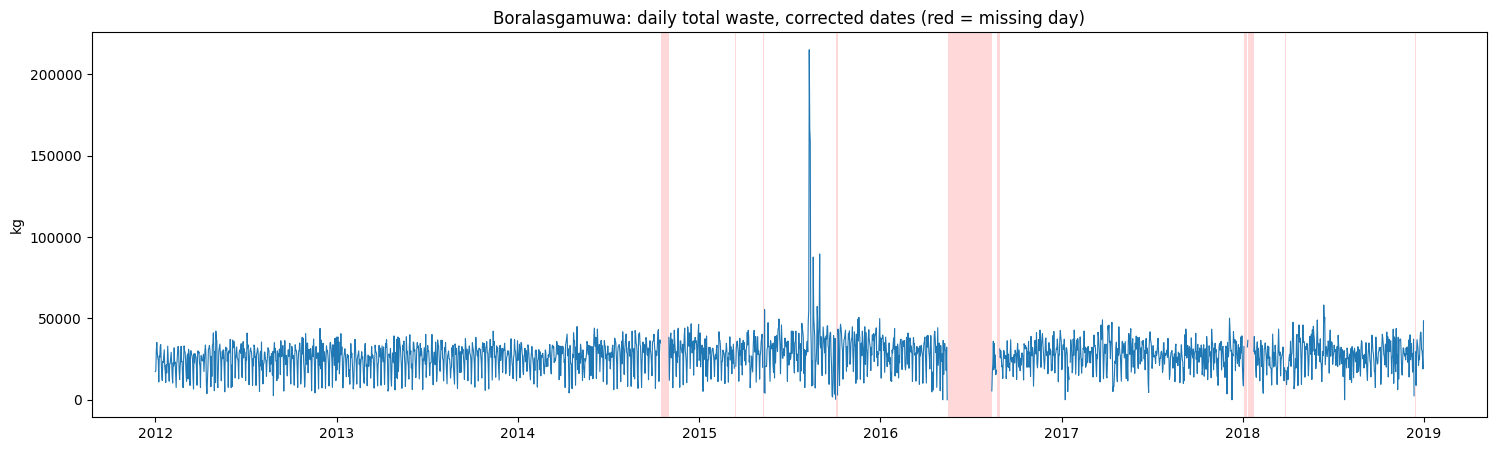

In [23]:
s = daily.reindex(full_range)
fig, ax = plt.subplots()
ax.plot(s.index, s.values, lw=0.8)
for d in missing_days:
    ax.axvspan(d, d + pd.Timedelta(days=1), color="red", alpha=0.15, lw=0)
ax.set_title(f"{NAME}: daily total waste, corrected dates (red = missing day)")
ax.set_ylabel("kg")
plt.show()

In [24]:
dd = daily.to_frame("kg")
dd["weekday"] = dd.index.day_name()
dd["month"] = dd.index.month
dd["year"] = dd.index.year
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

display(dd.groupby("weekday")["kg"].agg(["mean", "median", "count"]).reindex(order).round(0))
display(dd.groupby("month")["kg"].agg(["mean", "median", "count"]).round(0))
display(dd.groupby("year")["kg"].agg(["mean", "median", "count"]).round(0))

,mean,median,count
weekday,,,
Monday,27085.0,27010.0,346
Tuesday,32175.0,32195.0,344
Wednesday,32432.0,32135.0,348
Thursday,30906.0,30200.0,345
Friday,29069.0,29280.0,343
Saturday,25889.0,25955.0,346
Sunday,14193.0,13410.0,345


,mean,median,count
month,,,
1,25858.0,27050.0,199
2,25199.0,25595.0,198
3,26316.0,27735.0,214
4,26302.0,27125.0,210
5,27317.0,28810.0,198
6,29194.0,30395.0,180
7,27249.0,28125.0,186
8,28964.0,27500.0,199
9,26997.0,27450.0,210


,mean,median,count
year,,,
2012,24540.0,26485.0,366
2013,25332.0,26560.0,365
2014,27882.0,28820.0,349
2015,31485.0,31180.0,357
2016,27448.0,28650.0,271
2017,27811.0,28810.0,364
2018,27400.0,27960.0,345


/tmp/ipykernel_11319/2084828194.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot([dd.loc[dd["weekday"] == d, "kg"] for d in present_days], labels=[d[:3] for d in present_days])
/tmp/ipykernel_11319/2084828194.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot([dd.loc[dd["month"] == m, "kg"] for m in range(1, 13)], labels=list(range(1, 13)))


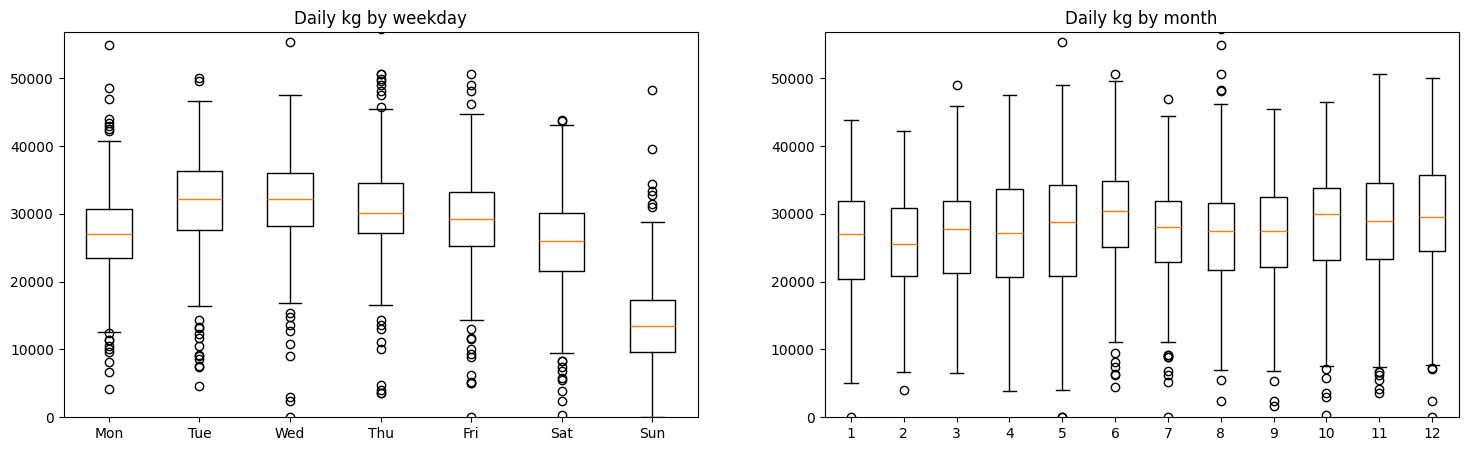

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
present_days = [d for d in order if (dd["weekday"] == d).any()]
axes[0].boxplot([dd.loc[dd["weekday"] == d, "kg"] for d in present_days], labels=[d[:3] for d in present_days])
axes[0].set_title("Daily kg by weekday")
axes[1].boxplot([dd.loc[dd["month"] == m, "kg"] for m in range(1, 13)], labels=list(range(1, 13)))
axes[1].set_title("Daily kg by month")
upper = dd["kg"].quantile(0.99) * 1.2
for a in axes:
    a.set_ylim(0, upper)
plt.show()

## 4. Preprocessing

### 4.1 Calendar days

In [26]:
START = pd.Timestamp("2012-01-01")
END = pd.Timestamp("2018-12-31")

In [27]:
prep = daily.reindex(pd.date_range(START, END, freq="D")).to_frame("net_weight_kg")
prep.index.name = "ticket_date"
prep["net_weight_kg_raw"] = prep["net_weight_kg"]
prep["is_weekend"] = prep.index.dayofweek >= 5
prep["is_missing"] = prep["net_weight_kg_raw"].isna()

In [28]:
print("Calendar:", START.date(), "to", END.date(), "|", len(prep), "days")
print("Days with recorded values:", int((~prep["is_missing"]).sum()), "| missing days:", int(prep["is_missing"].sum()))
last_in_range = prep.index[~prep["is_missing"]].max()
print("Last recorded day in range:", last_in_range.date(), "| days after it up to END:", int((prep.index > last_in_range).sum()))

Calendar: 2012-01-01 to 2018-12-31 | 2557 days
Days with recorded values: 2417 | missing days: 140
Last recorded day in range: 2018-12-31 | days after it up to END: 0


### 4.2 Weekly pattern

In [29]:
prep["is_closure_day"] = False
prep["is_closure_zero"] = False

In [30]:
obs = prep.loc[~prep["is_missing"], "net_weight_kg"]
obs.groupby(obs.index.day_name()).agg(["mean", "median", "count"]).reindex(order).round(0)

,mean,median,count
ticket_date,,,
Monday,27085.0,27010.0,346
Tuesday,32175.0,32195.0,344
Wednesday,32432.0,32135.0,348
Thursday,30906.0,30200.0,345
Friday,29069.0,29280.0,343
Saturday,25889.0,25955.0,346
Sunday,14193.0,13410.0,345


### 4.3 Outlier detection (same-weekday comparison)

In [31]:
Z_THRESHOLD = 3.5

local_med = pd.Series(np.nan, index=prep.index)
local_mad = pd.Series(np.nan, index=prep.index)
operating = prep["net_weight_kg"].where(~prep["is_closure_day"])    # closure days are not judged
for dow in range(7):
    s = operating[prep.index.dayofweek == dow]
    med = s.rolling(7, center=True, min_periods=3).median()
    local_med.loc[s.index] = med
    local_mad.loc[s.index] = (s - med).abs().rolling(7, center=True, min_periods=3).median()

prep["robust_z"] = 0.6745 * (operating - local_med) / local_mad.replace(0, np.nan)
prep["is_outlier"] = prep["robust_z"].abs() > Z_THRESHOLD
print("Outliers flagged:", int(prep["is_outlier"].sum()),
      "| on weekends:", int((prep["is_outlier"] & prep["is_weekend"]).sum()),
      f"| {prep['is_outlier'].sum() / prep['robust_z'].notna().sum() * 100:.1f} % of judged days")

# Sensitivity: how many days each threshold would flag (choose Z_THRESHOLD from this, then re-run)
display(pd.DataFrame({"threshold": [3.0, 3.5, 5.0, 7.0],
                      "days flagged": [int((prep["robust_z"].abs() > t).sum()) for t in [3.0, 3.5, 5.0, 7.0]]}))
prep.loc[prep["is_outlier"], ["net_weight_kg_raw", "robust_z"]].assign(
    weekday=lambda x: x.index.day_name(), same_weekday_median=local_med[prep["is_outlier"]]).round(1)

Outliers flagged: 137 | on weekends: 35 | 5.7 % of judged days


,threshold,days flagged
0,3.0,170
1,3.5,137
2,5.0,80
3,7.0,44


,net_weight_kg_raw,robust_z,weekday,same_weekday_median
ticket_date,,,,
2012-01-01,17340.0,6.9,Sunday,11405.0
2012-01-07,24330.0,3.6,Saturday,17445.0
2012-02-17,30310.0,5.1,Friday,24360.0
2012-02-20,19970.0,-4.0,Monday,22690.0
2012-03-07,12760.0,-75.4,Wednesday,28410.0
...,...,...,...,...
2018-11-03,37640.0,3.7,Saturday,28270.0
2018-11-09,6210.0,-13.2,Friday,27990.0
2018-11-17,18920.0,-3.7,Saturday,28520.0


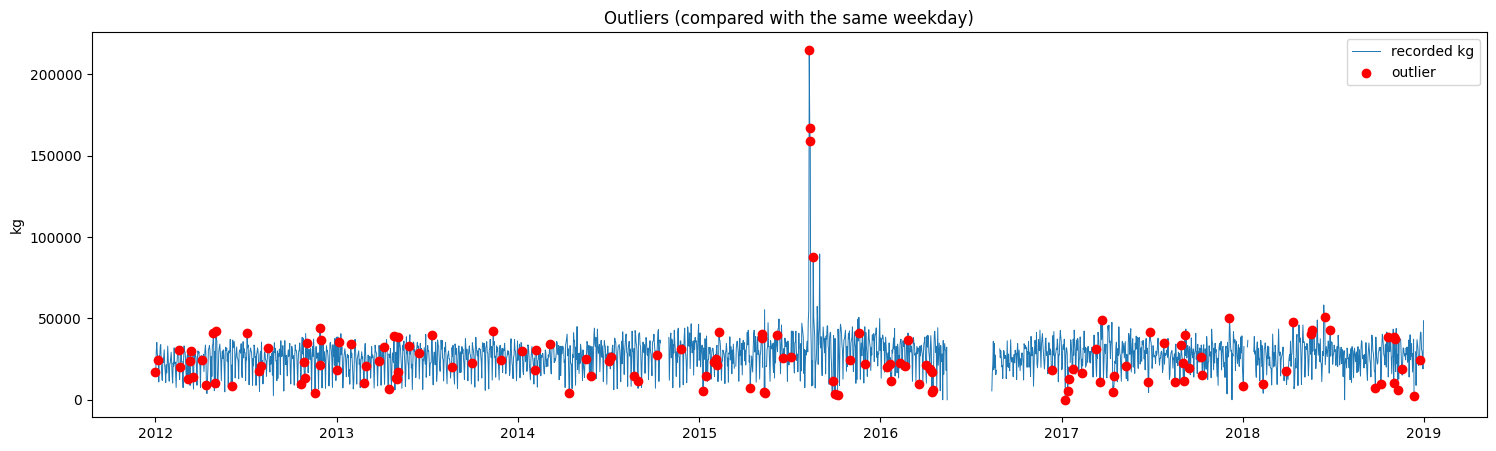

In [32]:
fig, ax = plt.subplots()
ax.plot(prep.index, prep["net_weight_kg_raw"], lw=0.7, label="recorded kg")
o = prep[prep["is_outlier"]]
ax.scatter(o.index, o["net_weight_kg_raw"], color="red", zorder=3, label="outlier")
ax.legend(); ax.set_ylabel("kg"); ax.set_title("Outliers (compared with the same weekday)")
plt.show()

In [33]:
# Outliers become gaps and are imputed together with the missing days
prep.loc[prep["is_outlier"], "net_weight_kg"] = np.nan
to_impute = prep["net_weight_kg"].isna()
print("Days to impute:", int(to_impute.sum()), f"({to_impute.mean() * 100:.1f} % of calendar days)",
      "| missing operating days:", int((prep["is_missing"] & ~prep["is_closure_zero"]).sum()),
      "| outliers:", int(prep["is_outlier"].sum()))

Days to impute: 277 (10.8 % of calendar days) | missing operating days: 140 | outliers: 137


### 4.4 Imputation with XGBoost

In [34]:
def make_features(series, lag_count):
    X = pd.DataFrame(index=series.index)
    X = pd.concat([X] + [series.shift(i).rename(f"lag_{i}") for i in range(1, lag_count + 1)], axis=1)
    X["dayofweek"] = series.index.dayofweek
    X["is_weekend"] = (series.index.dayofweek >= 5).astype(int)
    X["month"] = series.index.month
    return X

def splits(index):
    n = len(index)
    return index[: int(n * 0.6)], index[int(n * 0.6): int(n * 0.8)], index[int(n * 0.8):]

target = prep["net_weight_kg"]                 # gaps and outliers are NaN; missing closure days are 0
known_days = target.index[target.notna() & ~prep["is_closure_zero"]]    # real recorded days only
train_idx, val_idx, test_idx = splits(known_days)
print("train / val / test real days:", len(train_idx), len(val_idx), len(test_idx))
print("test period:", test_idx.min().date(), "to", test_idx.max().date())

train / val / test real days: 1368 456 456
test period: 2017-08-16 to 2018-12-31


In [35]:
lag_list = [7, 14, 28]
depth_list = [3, 5]
estimator_list = [200, 500]
eta_list = [0.03, 0.1]

results = []
for lag in lag_list:
    X = make_features(target, lag)
    for depth in depth_list:
        for n_est in estimator_list:
            for eta in eta_list:
                model = xgboost.XGBRegressor(n_estimators=n_est, max_depth=depth, learning_rate=eta,
                                             subsample=0.8, objective="reg:squarederror",
                                             random_state=0, n_jobs=-1)
                model.fit(X.loc[train_idx], target.loc[train_idx])
                pred = model.predict(X.loc[val_idx])
                results.append({"lag_count": lag, "max_depth": depth, "n_estimators": n_est, "eta": eta,
                                "val_rmse": sqrt(mean_squared_error(target.loc[val_idx], pred)),
                                "val_mae": mean_absolute_error(target.loc[val_idx], pred)})

results_df = pd.DataFrame(results).sort_values("val_rmse").reset_index(drop=True)
results_df.head(10)

,lag_count,max_depth,n_estimators,eta,val_rmse,val_mae
0,28,3,200,0.03,6137.296155,4591.764216
1,14,3,200,0.03,6181.287242,4675.926578
2,28,3,500,0.03,6184.320708,4623.167054
3,28,3,200,0.10,6190.931015,4661.229672
4,28,5,200,0.03,6230.425772,4673.669960
5,14,3,200,0.10,6239.199557,4785.860257
6,28,3,500,0.10,6244.200275,4706.032758
7,14,3,500,0.03,6246.595553,4732.373471
8,28,5,500,0.03,6257.541185,4686.359107
9,7,3,200,0.03,6285.954544,4841.429807


Best settings: {'lag_count': 28.0, 'max_depth': 3.0, 'n_estimators': 200.0, 'eta': 0.03, 'val_rmse': 6137.296154736748, 'val_mae': 4591.764215837446}
Test  XGBoost   RMSE 6,694 | MAE 5,066
Test  lag-7     RMSE 9,169 | MAE 6,934


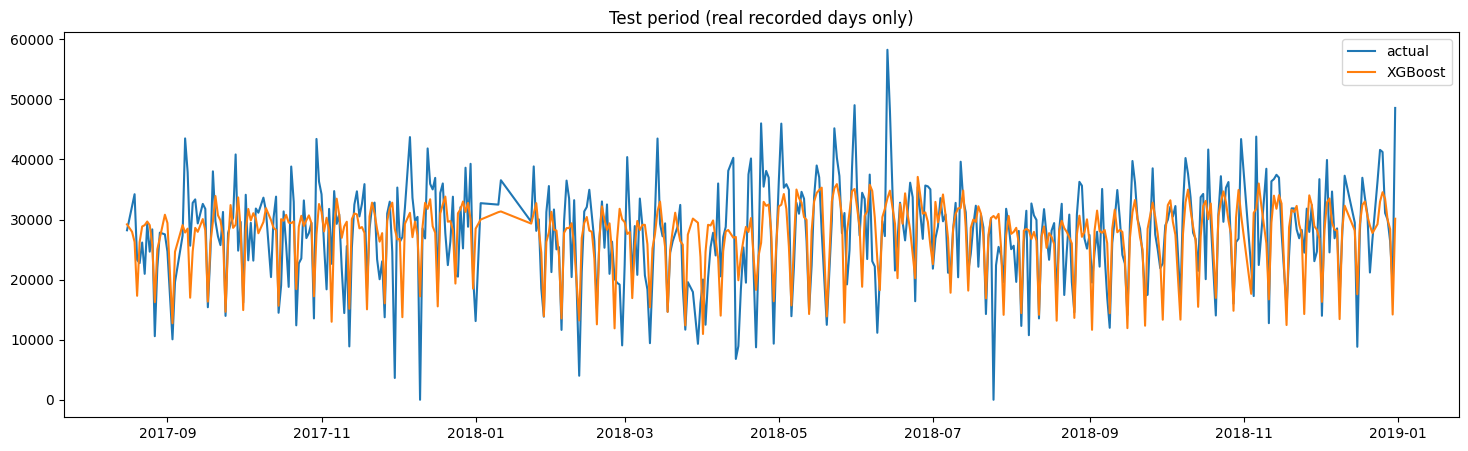

In [36]:
best = results_df.iloc[0]
LAG = int(best["lag_count"])
print("Best settings:", best.to_dict())

X = make_features(target, LAG)
fit_idx = train_idx.append(val_idx)
best_model = xgboost.XGBRegressor(n_estimators=int(best["n_estimators"]), max_depth=int(best["max_depth"]),
                                  learning_rate=float(best["eta"]), subsample=0.8,
                                  objective="reg:squarederror", random_state=0, n_jobs=-1)
best_model.fit(X.loc[fit_idx], target.loc[fit_idx])
test_pred = best_model.predict(X.loc[test_idx])

y_test = target.loc[test_idx]
baseline = target.shift(7).loc[test_idx]
ok = baseline.notna()
print(f"Test  XGBoost   RMSE {sqrt(mean_squared_error(y_test, test_pred)):,.0f} | MAE {mean_absolute_error(y_test, test_pred):,.0f}")
print(f"Test  lag-7     RMSE {sqrt(mean_squared_error(y_test[ok], baseline[ok])):,.0f} | MAE {mean_absolute_error(y_test[ok], baseline[ok]):,.0f}")

plt.plot(y_test.index, y_test.values, label="actual")
plt.plot(y_test.index, test_pred, label="XGBoost")
plt.title("Test period (real recorded days only)"); plt.legend(); plt.show()

In [37]:
# from tqdm.auto import tqdm

# full_grid = [(l, n, d, s, e) for l in [14, 42, 49, 90, 120, 150, 360] for n in [10, 100, 1000]
#              for d in [3, 4, 6, 7, 8, 9] for s in [0.6, 0.7, 0.8, 0.9] for e in [0.01, 0.1, 0.3]]
# small_grid = [(l, n, d, 0.8, e) for l in lag_list for n in estimator_list for d in depth_list for e in eta_list]

# feature_cache = {}
# def features(lag):
#     if lag not in feature_cache:
#         feature_cache[lag] = make_features(target, lag)
#     return feature_cache[lag]

# def search(grid, label):
#     best = None
#     for lag, n, d, s, e in tqdm(grid, desc=label, unit="model"):   # shows done / remaining / time left
#         X = features(lag)
#         m = xgboost.XGBRegressor(n_estimators=n, max_depth=d, subsample=s, learning_rate=e,
#                                  objective="reg:squarederror", random_state=0, n_jobs=-1)
#         m.fit(X.loc[train_idx], target.loc[train_idx])
#         rmse = sqrt(mean_squared_error(target.loc[val_idx], m.predict(X.loc[val_idx])))
#         if best is None or rmse < best[0]:
#             best = (rmse, lag, n, d, s, e)
#     rmse, lag, n, d, s, e = best
#     X = features(lag)
#     m = xgboost.XGBRegressor(n_estimators=n, max_depth=d, subsample=s, learning_rate=e,
#                              objective="reg:squarederror", random_state=0, n_jobs=-1)
#     m.fit(X.loc[fit_idx], target.loc[fit_idx])
#     err = target.loc[test_idx] - m.predict(X.loc[test_idx])
#     summary = {"configs": len(grid), "val_rmse": round(rmse), "test_rmse": round(sqrt((err ** 2).mean())),
#                "lag": lag, "n_estimators": n, "max_depth": d, "subsample": s, "eta": e}
#     return summary, err

# small, err_small = search(small_grid, f"Reduced grid ({len(small_grid)} models)")
# full, err_full = search(full_grid, f"Original grid ({len(full_grid)} models)")
# display(pd.DataFrame([small, full], index=["reduced grid", "original grid"]))

# # Bootstrap the test days: is the test RMSE difference real or noise?
# rng = np.random.default_rng(0)
# diffs = []
# for _ in range(2000):
#     i = rng.integers(0, len(err_small), len(err_small))
#     diffs.append(sqrt((err_small.iloc[i] ** 2).mean()) - sqrt((err_full.iloc[i] ** 2).mean()))
# lo, hi = np.percentile(diffs, [2.5, 97.5])
# print(f"Test RMSE difference (reduced - original): {small['test_rmse'] - full['test_rmse']:,} kg | "
#       f"95% CI [{lo:,.0f}, {hi:,.0f}] kg")

In [38]:
# Refit on all real days, then fill gaps in time order so later gaps can use earlier filled values
final_model = xgboost.XGBRegressor(n_estimators=int(best["n_estimators"]), max_depth=int(best["max_depth"]),
                                   learning_rate=float(best["eta"]), subsample=0.8,
                                   objective="reg:squarederror", random_state=0, n_jobs=-1)
final_model.fit(make_features(target, LAG).loc[known_days], target.loc[known_days])

filled = target.copy()
for day in filled.index[filled.isna()]:
    pos = filled.index.get_loc(day)
    row = {f"lag_{i}": (filled.iloc[pos - i] if pos - i >= 0 else np.nan) for i in range(1, LAG + 1)}
    row["dayofweek"] = day.dayofweek
    row["is_weekend"] = int(day.dayofweek >= 5)
    row["month"] = day.month
    filled.loc[day] = max(float(final_model.predict(pd.DataFrame([row]))[0]), 0.0)

prep["is_imputed"] = prep["net_weight_kg"].isna()
prep["net_weight_kg"] = filled

imp = prep.loc[prep["is_imputed"], "net_weight_kg"]
print("Imputed values:", len(imp), f"({len(imp) / len(prep) * 100:.2f} % of all days)")
real = prep.loc[~prep["is_imputed"] & ~prep["is_closure_zero"], "net_weight_kg"]
print(f"Mean imputed: {imp.mean():,.0f} kg | mean recorded: {real.mean():,.0f} kg")
print("Imputed per weekday:", prep.loc[prep["is_imputed"]].index.day_name().value_counts().reindex(order, fill_value=0).to_dict())
print("Blanks left:", int(prep["net_weight_kg"].isna().sum()))

Imputed values: 277 (10.83 % of all days)
Mean imputed: 27,491 kg | mean recorded: 27,441 kg
Imputed per weekday: {'Monday': 36, 'Tuesday': 40, 'Wednesday': 42, 'Thursday': 34, 'Friday': 50, 'Saturday': 43, 'Sunday': 32}
Blanks left: 0


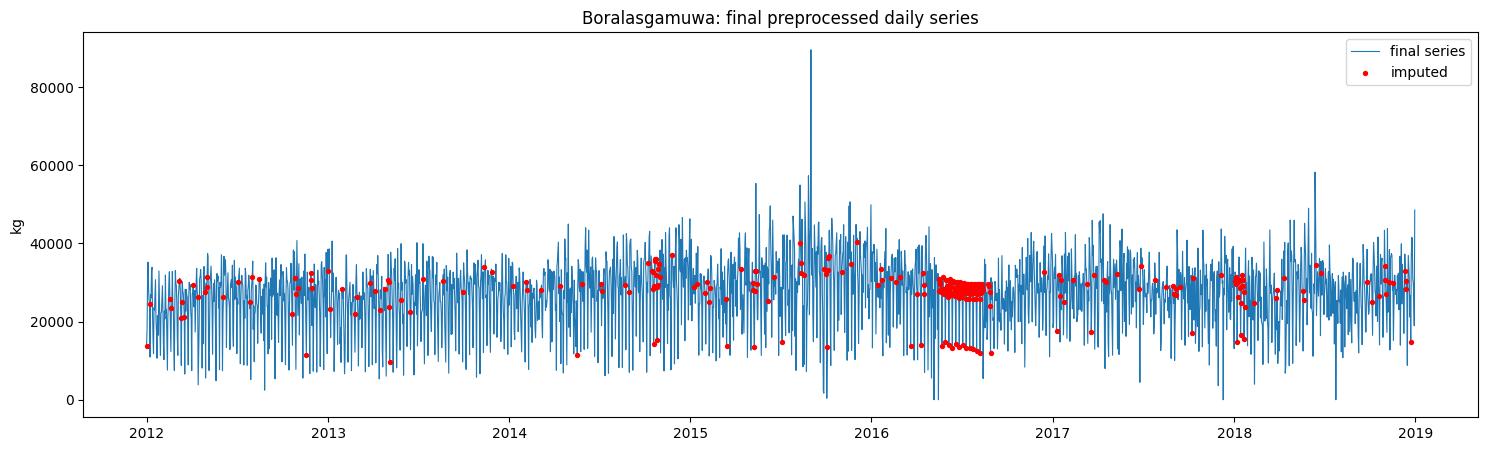

In [39]:
fig, ax = plt.subplots()
ax.plot(prep.index, prep["net_weight_kg"], lw=0.8, label="final series")
i = prep[prep["is_imputed"]]
ax.scatter(i.index, i["net_weight_kg"], s=8, color="red", zorder=3, label="imputed")
ax.set_title(f"{NAME}: final preprocessed daily series"); ax.set_ylabel("kg"); ax.legend()
plt.show()

In [40]:
prep.columns

Index(['net_weight_kg', 'net_weight_kg_raw', 'is_weekend', 'is_missing', 'is_closure_day', 'is_closure_zero', 'robust_z', 'is_outlier', 'is_imputed'], dtype='object')

In [41]:
df.columns

Index(['area', 'ticket_date', 'waste_type', 'net_weight_kg', 'ticket_date_original', 'date_swapped'], dtype='object')

In [42]:
df.isna().sum()

,0
area,0
ticket_date,0
waste_type,0
net_weight_kg,0
ticket_date_original,0
date_swapped,0


### 4.5 Export

In [43]:
OUT_PATH = "daily_waste_output_boralasgamuwa_datefixed.csv"
DETAILS_PATH = "daily_waste_output_datefixed_boralasgamuwa_details.csv"

In [44]:
prep.head(5)

,net_weight_kg,net_weight_kg_raw,is_weekend,is_missing,is_closure_day,is_closure_zero,robust_z,is_outlier,is_imputed
ticket_date,,,,,,,,,
2012-01-01,13832.737305,17340.0,True,False,False,False,6.901996,True,True
2012-01-02,17780.000000,17780.0,False,False,False,False,-1.101722,False,False
2012-01-03,30020.000000,30020.0,False,False,False,False,0.864664,False,False
2012-01-04,35210.000000,35210.0,False,False,False,False,0.626278,False,False
2012-01-05,28590.000000,28590.0,False,False,False,False,-0.822007,False,False


In [45]:
out = prep.reset_index()[["ticket_date", "net_weight_kg"]]
out.head()

,ticket_date,net_weight_kg
0,2012-01-01,13832.737305
1,2012-01-02,17780.000000
2,2012-01-03,30020.000000
3,2012-01-04,35210.000000
4,2012-01-05,28590.000000


In [46]:
out.to_csv(OUT_PATH, index=False)
print("Saved model input:", OUT_PATH, out.shape)

Saved model input: daily_waste_output_boralasgamuwa_datefixed.csv (2557, 2)


In [47]:
details = prep.reset_index()[["ticket_date", "net_weight_kg", "net_weight_kg_raw",
                          "is_weekend", "is_missing", "is_closure_zero", "is_outlier", "is_imputed"]]
details.to_csv(DETAILS_PATH, index=False)
print("Saved:", OUT_PATH, out.shape)

Saved: daily_waste_output_boralasgamuwa_datefixed.csv (2557, 2)


In [48]:
details.head()

,ticket_date,net_weight_kg,net_weight_kg_raw,is_weekend,is_missing,is_closure_zero,is_outlier,is_imputed
0,2012-01-01,13832.737305,17340.0,True,False,False,True,True
1,2012-01-02,17780.000000,17780.0,False,False,False,False,False
2,2012-01-03,30020.000000,30020.0,False,False,False,False,False
3,2012-01-04,35210.000000,35210.0,False,False,False,False,False
4,2012-01-05,28590.000000,28590.0,False,False,False,False,False
